In [1]:
import numpy as np
import matplotlib.pyplot as plt
import itertools
from numba import jit
from scipy import interpolate
from scipy.optimize import minimize

In [2]:
def p_from_n(n,k,gam):
    result = k*((n)**gam)
    return result

def p_from_mu(k,n,mu_b,mu,gam):
    mu = k*(((n**(gam-1))+(((gam-1)/(k*gam))*(mu-mu_b)))**(gam/(gam-1)))
    return mu

def k(p_initial,n_initial,gam):
    result = p_initial/(n_initial**gam)
    return result

def mu_from_p(p,k,gam,n_intial,mu_initial):
    term1 = (((p/k)**((gam-1)/gam))-n_intial**(gam-1))*((k*gam)/gam-1)
    term2 = mu_initial
    result = term1 +term2
    return result

def n_from_p(p,k,gam):
    result = (p/k)**(1/gam)
    return result

def e_from_p(p,n,mu):
    result = (n*mu)-p
    return result

In [3]:
p_initial_had = 3.542
mu_initial_had = 977.5

n0 = 0.16
n_intial_had = 1.1*n0
gam_had = 2
k_had=k(p_initial_had,n_intial_had,gam_had)

n_pt = 6.7*n0

n_had = np.linspace(n_intial_had,n_pt,100)
p_had = p_from_n(n_had,k_had,gam_had)
mu_had = mu_from_p(p_had,k_had,gam_had,n_intial_had,mu_initial_had)

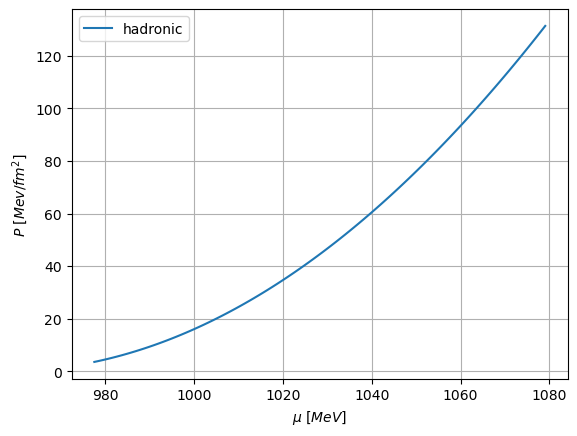

In [4]:
plt.plot(mu_had, p_had, label = "hadronic")

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()

In [5]:
gam_quark = 2
delta_n = 4*n_pt
mu_initial_quark = mu_had[-1]
n_initial_quark = n_pt + delta_n
k_quark=k(p_had[-1],n_initial_quark,gam_quark)

n_quark = np.linspace(n_initial_quark,20,100)
p_quark = p_from_n(n_quark,k_quark,gam_quark)
mu_quark = mu_from_p(p_quark,k_quark,gam_quark,n_initial_quark,mu_initial_quark)

In [6]:
n_quark

array([ 5.36      ,  5.50787879,  5.65575758,  5.80363636,  5.95151515,
        6.09939394,  6.24727273,  6.39515152,  6.5430303 ,  6.69090909,
        6.83878788,  6.98666667,  7.13454545,  7.28242424,  7.43030303,
        7.57818182,  7.72606061,  7.87393939,  8.02181818,  8.16969697,
        8.31757576,  8.46545455,  8.61333333,  8.76121212,  8.90909091,
        9.0569697 ,  9.20484848,  9.35272727,  9.50060606,  9.64848485,
        9.79636364,  9.94424242, 10.09212121, 10.24      , 10.38787879,
       10.53575758, 10.68363636, 10.83151515, 10.97939394, 11.12727273,
       11.27515152, 11.4230303 , 11.57090909, 11.71878788, 11.86666667,
       12.01454545, 12.16242424, 12.31030303, 12.45818182, 12.60606061,
       12.75393939, 12.90181818, 13.04969697, 13.19757576, 13.34545455,
       13.49333333, 13.64121212, 13.78909091, 13.9369697 , 14.08484848,
       14.23272727, 14.38060606, 14.52848485, 14.67636364, 14.82424242,
       14.97212121, 15.12      , 15.26787879, 15.41575758, 15.56

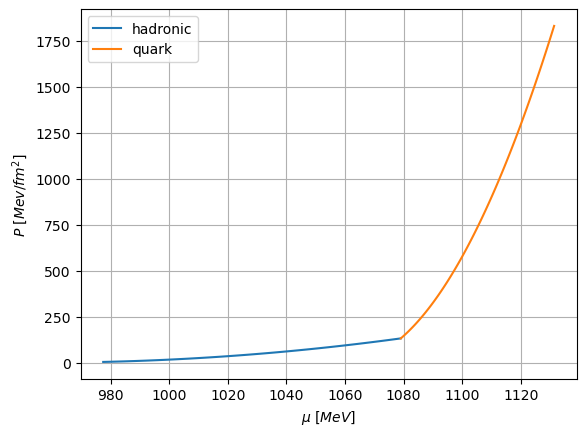

In [7]:
plt.plot(mu_had, p_had, label = "hadronic")
plt.plot(mu_quark, p_quark, label = "quark")

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()

In [8]:
# Combine hadronic and quark phases
mu_total = np.concatenate((mu_had, mu_quark))
p_total = np.concatenate((p_had, p_quark))
n_total = np.concatenate((n_had,n_quark))
e_total = e_from_p(p_total, n_total, mu_total)

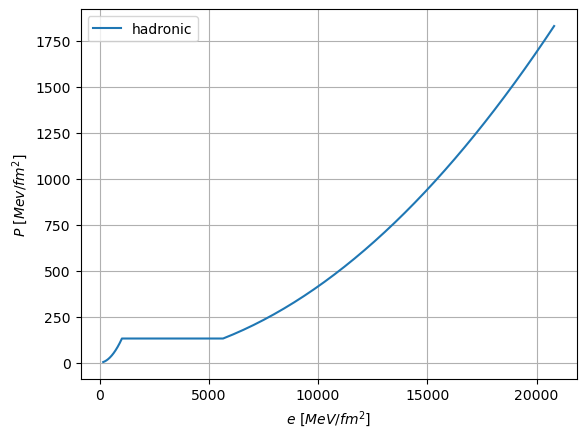

In [9]:
plt.plot(e_total, p_total, label = "hadronic")

plt.xlabel(r"$e \ [MeV/fm^2]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()

In [10]:
cs2 = np.gradient(p_total,e_total)

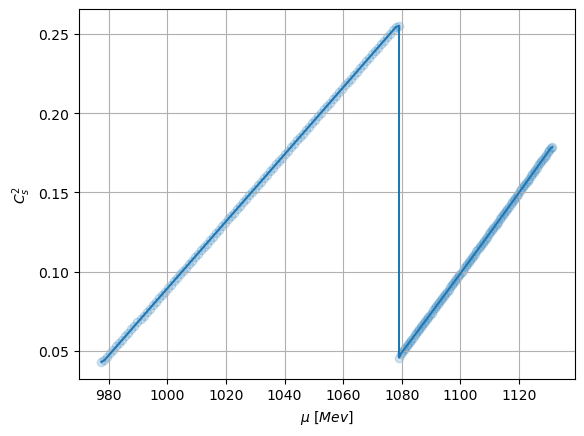

In [11]:
plt.scatter(mu_total,cs2,alpha=0.2);
plt.plot(mu_total,cs2)
plt.grid()
plt.xlabel(r"$\mu \ [Mev]$")
plt.ylabel(r"$C_s^2$")
plt.show();

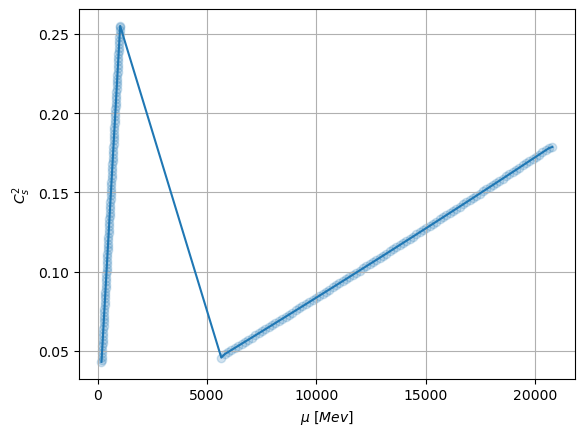

In [12]:
plt.scatter(e_total,cs2,alpha=0.2);
plt.plot(e_total,cs2)
plt.grid()
plt.xlabel(r"$\mu \ [Mev]$")
plt.ylabel(r"$C_s^2$")
plt.show();

In [13]:
P_crit_1 = p_had[-1]*(1+0.01)
P_crit_2 = p_had[-1]*(1+7)
P_crit_new = np.linspace(P_crit_1,P_crit_2,1000)

In [14]:
P_crit_new

array([ 132.71932545,  133.63876775,  134.55821005,  135.47765235,
        136.39709465,  137.31653695,  138.23597925,  139.15542155,
        140.07486384,  140.99430614,  141.91374844,  142.83319074,
        143.75263304,  144.67207534,  145.59151764,  146.51095993,
        147.43040223,  148.34984453,  149.26928683,  150.18872913,
        151.10817143,  152.02761373,  152.94705603,  153.86649832,
        154.78594062,  155.70538292,  156.62482522,  157.54426752,
        158.46370982,  159.38315212,  160.30259441,  161.22203671,
        162.14147901,  163.06092131,  163.98036361,  164.89980591,
        165.81924821,  166.73869051,  167.6581328 ,  168.5775751 ,
        169.4970174 ,  170.4164597 ,  171.335902  ,  172.2553443 ,
        173.1747866 ,  174.09422889,  175.01367119,  175.93311349,
        176.85255579,  177.77199809,  178.69144039,  179.61088269,
        180.53032498,  181.44976728,  182.36920958,  183.28865188,
        184.20809418,  185.12753648,  186.04697878,  186.96642

In [15]:
P_crit_1

132.71932545454544

In [16]:
a =[]
b =[]
P_opt=[]
for P in P_crit_new:
    # Define your points
    x1, y1 = mu_had[0], p_had[0]
    x2, y2 = mu_had[-1], P

    x_points = mu_quark
    y_points = p_quark

    # For inequality constraint defining hadronic part.
    x_values = np.array(mu_had[1:])  # Hadronic Part x_values
    f_values = np.array(p_had[1:])    # Corresponding y_values

    x_values_1 = np.array(mu_quark[1:])  
    f_values_1 = np.array(p_quark[1:])

    # Define the quadratic function
    def quadratic(x, a, b):
        return a * (x - x2)**2 + b * (x - x2) + y2

    # Objective function: sum of squared differences
    def objective(params):
        a, b = params
        return 0

    # Initial guess for parameters
    initial_guess = [0, 0]

    # Constraints to pass through (x1, y1)
    def eq_constraint(params):
        a, b = params
        return quadratic(x1, a, b) - y1

    def ineq_constraint(params):
        a, b = params
        return quadratic(x_values, a, b) - f_values
    def ineq_constraint_1(params):
        a, b = params
        return quadratic(x_values_1, a, b) - f_values_1

    # Define the constraint in the form required by 'minimize'
    constraints = [
        {'type': 'eq', 'fun': eq_constraint},
        {'type': 'ineq', 'fun': ineq_constraint},
        {'type': 'ineq', 'fun': ineq_constraint_1}
    ]
    # Perform the optimization
    result = minimize(objective, initial_guess, constraints=constraints)
    
    if result.success:
        a_opt, b_opt = result.x
        a.append(a_opt)
        b.append(b_opt)
        P_opt.append(P)
        print(f"For P_crit = {P}: Optimal parameters found: a = {a_opt}, b = {b_opt}")

For P_crit = 809.4288572699973: Optimal parameters found: a = 0.07513611321821345, b = 15.565909322008963
For P_crit = 810.3482995686595: Optimal parameters found: a = 0.07496308021207827, b = 15.557389664425338
For P_crit = 811.2677418673218: Optimal parameters found: a = 0.07479004720594443, b = 15.54887000684178
For P_crit = 812.187184165984: Optimal parameters found: a = 0.07461701419980882, b = 15.54035034925818
For P_crit = 813.1066264646464: Optimal parameters found: a = 0.07444398119367233, b = 15.531830691674354
For P_crit = 814.0260687633087: Optimal parameters found: a = 0.07427094818753849, b = 15.523311034090932
For P_crit = 814.9455110619709: Optimal parameters found: a = 0.07409791518140289, b = 15.514791376507196
For P_crit = 815.8649533606333: Optimal parameters found: a = 0.07392488217526684, b = 15.506271718923484
For P_crit = 816.7843956592956: Optimal parameters found: a = 0.07375184916913255, b = 15.497752061339948
For P_crit = 817.7038379579578: Optimal parameter

In [17]:
mu_quad = np.linspace(mu_had[0],1130,1000)
P_quad = a[-1] * (mu_quad - x2)**2 + b[-1] * (mu_quad - x2) + y2

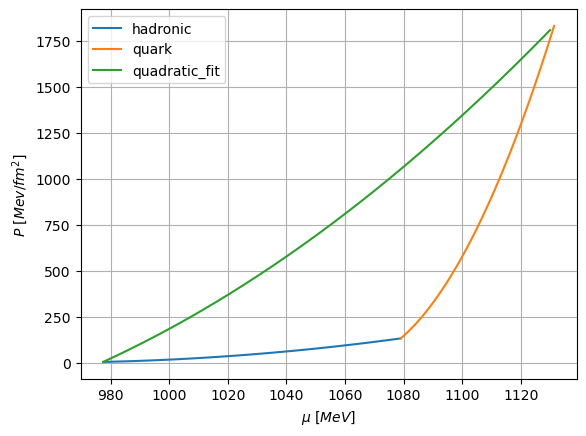

In [18]:
plt.plot(mu_had, p_had, label = "hadronic")
plt.plot(mu_quark, p_quark, label = "quark")
plt.plot(mu_quad,P_quad,label="quadratic_fit")

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
#plt.xlim([950,1800])
#plt.ylim([0,600])
plt.grid()

In [19]:
def p_from_n(n,k,gam):
    result = k*((n)**gam)
    return result

def p_from_mu(k,n,mu_b,mu,gam):
    mu = k*(((n**(gam-1))+(((gam-1)/(k*gam))*(mu-mu_b)))**(gam/(gam-1)))
    return mu

def k(p_initial,n_initial,gam):
    result = p_initial/(n_initial**gam)
    return result

def mu_from_p(p,k,gam,n_intial,mu_initial):
    term1 = (((p/k)**((gam-1)/gam))-n_intial**(gam-1))*((k*gam)/gam-1)
    term2 = mu_initial
    result = term1 +term2
    return result

def n_from_p(p,k,gam):
    result = (p/k)**(1/gam)
    return result

def e_from_p(p,n,mu):
    result = (n*mu)-p
    return result

n0 = 0.16  # Nuclear saturation density
n_pt_array = np.linspace(1.1, 8, 10) * n0
gam_had_array = np.linspace(1.1, 4, 10)
gam_quark_array = np.linspace(0.5, 4, 10)

mu, p, e, n = [], [], [], []

# Combine the arrays into one loop using itertools.product
for n_pt, gam_had, gam_quark in itertools.product(n_pt_array, gam_had_array, gam_quark_array):

    # Calculate delta_n_array for the current n_pt
    delta_n_array = np.linspace(0, 9.09, 100) * n_pt

    # Iterate over delta_n_array
    for delta_n in delta_n_array:
        p_initial_had = 3.542
        mu_initial_had = 977.5

        n_initial_had = 1.1 * n0
        k_had=k(p_initial_had,n_intial_had,gam_had)

        n_had = np.linspace(n_intial_had,n_pt,100)
        p_had = p_from_n(n_had,k_had,gam_had)
        mu_had = mu_from_p(p_had,k_had,gam_had,n_intial_had,mu_initial_had)


        # Pressure and chemical potential at phase transition
        mu_initial_quark = mu_had[-1]
        n_initial_quark = n_pt + delta_n
        k_quark=k(p_had[-1],n_initial_quark,gam_quark)

        n_quark = np.linspace(n_initial_quark,20,100)
        p_quark = p_from_n(n_quark,k_quark,gam_quark)
        mu_quark = mu_from_p(p_quark,k_quark,gam_quark,n_initial_quark,mu_initial_quark)

        mu_total = np.concatenate((mu_had, mu_quark))
        p_total = np.concatenate((p_had, p_quark))
        n_total = np.concatenate((n_had,n_quark))
        e_total = e_from_p(p_total, n_total, mu_total)

        mu.append(mu_total)
        p.append(p_total)
        e.append(e_total)


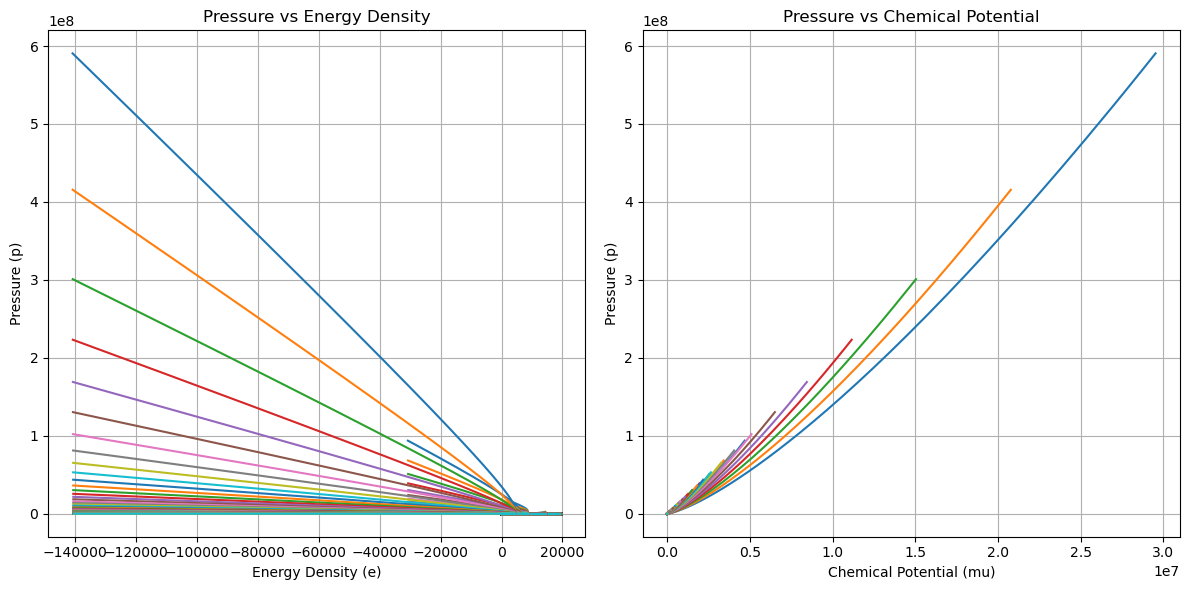

In [20]:
# Create a 2x1 grid of subplots to include both curves in one plot
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# After the loop, plot concatenated data
for i in range(1000):
    # Plot 1: Pressure vs Energy Density
    axes[0].plot(e[i], p[i], label=f"Curve {i+1}")

    # Plot 2: Pressure vs Chemical Potential
    axes[1].plot(mu[i], p[i], label=f"Curve {i+1}")

# Adding titles, labels, and legends after the loop

# Plot 1: Pressure vs Energy Density
axes[0].set_title('Pressure vs Energy Density')
axes[0].set_xlabel('Energy Density (e)')
axes[0].set_ylabel('Pressure (p)')
axes[0].grid(True)

# Plot 2: Pressure vs Chemical Potential
axes[1].set_title('Pressure vs Chemical Potential')
axes[1].set_xlabel('Chemical Potential (mu)')
axes[1].set_ylabel('Pressure (p)')
axes[1].grid(True)

# Optionally add legends (uncomment to show)
# axes[0].legend()
# axes[1].legend()

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()
